# Flow Matching

A minimal, tested implementation of flow matching, validated on a 2D bimodal distribution.
learns a velocity field that transports samples from a Gaussian prior onto a target distribution.
Two moons is used as the target because it is the smallest case that exposes what this method is for: a model that regresses a conditional mean collapses the two crescents into the empty space between them, while a correct transport populates both.

**Reference.** Lipman et al., Flow Matching for Generative Modeling, ICLR 2023.

In [ ]:
PINNED_TORCH = "2.9.1+cu126"

import torch

# The pin only matters on GPU runtimes: torch 2.11 built against CUDA 13 raises a
# floating-point exception in the fused dropout kernels under this workload.
# CPU sessions (data parsing, shape debugging) run on whatever ships with Colab.
if not torch.cuda.is_available():
    print(f"CPU runtime — torch {torch.__version__}, pin not required.")
elif torch.__version__ != PINNED_TORCH:
    print(f"Found torch {torch.__version__}, installing {PINNED_TORCH}.")
    !pip -q install torch=={PINNED_TORCH} --index-url https://download.pytorch.org/whl/cu126
    print("\nRestart the runtime, then re-run this cell to confirm the pin.")
else:
    print(f"torch {torch.__version__} — pin satisfied.")

CPU runtime — torch 2.11.0+cpu, pin not required.


In [ ]:
import math
import os
import random
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int = 0) -> None:
    """Seed Python, NumPy and Torch for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(0)
print(f"torch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"gpu: {torch.cuda.get_device_name(0)}")

torch 2.11.0+cpu | device: cpu


In [ ]:
def _broadcast_t(t: torch.Tensor, like: torch.Tensor) -> torch.Tensor:
    """Reshape a per-sample time (B,) so it broadcasts against `like` (B, ...)."""
    return t.view(t.shape[0], *([1] * (like.dim() - 1)))


def sample_time(batch_size: int, device, schedule: str = "uniform") -> torch.Tensor:
    """Draw per-sample times in (0, 1)."""
    if schedule == "uniform":
        return torch.rand(batch_size, device=device)
    if schedule == "logit_normal":
        return torch.sigmoid(torch.randn(batch_size, device=device))
    raise ValueError(f"unknown time schedule: {schedule!r}")


def linear_path(x1: torch.Tensor, t: torch.Tensor, x0: torch.Tensor | None = None):
    """Optimal-transport conditional path.

    Returns the interpolant x_t, the target velocity u_t = x1 - x0, and the prior
    sample x0 that was used.
    """
    if x0 is None:
        x0 = torch.randn_like(x1)
    t_b = _broadcast_t(t, x1)
    x_t = (1.0 - t_b) * x0 + t_b * x1
    u_t = x1 - x0
    return x_t, u_t, x0


def flow_matching_loss(
    velocity_fn,
    x1: torch.Tensor,
    mask: torch.Tensor | None = None,
    time_schedule: str = "uniform",
    x0: torch.Tensor | None = None,
    t: torch.Tensor | None = None,
) -> torch.Tensor:
    """Conditional flow matching objective.

    velocity_fn: callable (x_t, t) -> predicted velocity, same shape as x_t.
                 Scene conditioning is expected to be closed over by the caller.
    mask:        optional (B, ...) float mask broadcastable to x1, for padded
                 timesteps that should not contribute to the loss.
    x0, t:       optionally supplied rather than drawn, which makes validation
                 loss deterministic across epochs and leaves room for coupled
                 (minibatch-OT) pairings of prior and data samples.
    """
    if t is None:
        t = sample_time(x1.shape[0], x1.device, time_schedule)
    x_t, u_t, _ = linear_path(x1, t, x0)
    v_pred = velocity_fn(x_t, t)

    sq_err = (v_pred - u_t).pow(2)
    if mask is None:
        return sq_err.mean()
    mask = mask.to(sq_err.dtype).expand_as(sq_err)
    return (sq_err * mask).sum() / mask.sum().clamp_min(1.0)


@torch.no_grad()
def integrate(
    velocity_fn,
    x0: torch.Tensor,
    n_steps: int = 10,
    method: str = "euler",
    return_path: bool = False,
):
    """Integrate dx/dt = v(x, t) from t=0 to t=1."""
    x = x0
    dt = 1.0 / n_steps
    path = [x] if return_path else None

    for i in range(n_steps):
        t = torch.full((x.shape[0],), i * dt, device=x.device, dtype=x.dtype)
        if method == "euler":
            x = x + dt * velocity_fn(x, t)
        elif method == "midpoint":
            v1 = velocity_fn(x, t)
            x_mid = x + 0.5 * dt * v1
            x = x + dt * velocity_fn(x_mid, t + 0.5 * dt)
        else:
            raise ValueError(f"unknown integrator: {method!r}")
        if return_path:
            path.append(x)

    return (x, torch.stack(path)) if return_path else x

In [ ]:
def _check_flow_matching_core() -> None:
    """Shape and correctness checks on the transport utilities."""
    torch.manual_seed(0)
    B, T, D = 32, 16, 3
    x1 = torch.randn(B, T, D)

    # Endpoints of the linear path.
    x_t0, u, x0 = linear_path(x1, torch.zeros(B))
    x_t1, _, _ = linear_path(x1, torch.ones(B), x0)
    assert torch.allclose(x_t0, x0, atol=1e-6), "t=0 must return the prior sample"
    assert torch.allclose(x_t1, x1, atol=1e-6), "t=1 must return the data sample"
    assert torch.allclose(u, x1 - x0, atol=1e-6)

    # An oracle that knows the true conditional velocity must transport x0 onto x1
    # exactly, in a single Euler step, because the OT path is straight.
    oracle = lambda x, t: (x1 - x0)
    assert torch.allclose(integrate(oracle, x0, n_steps=1), x1, atol=1e-5)
    assert torch.allclose(integrate(oracle, x0, n_steps=37), x1, atol=1e-5)
    assert torch.allclose(integrate(oracle, x0, n_steps=4, method="midpoint"), x1, atol=1e-5)

    # A perfect model scores zero loss. x0 is pinned so the oracle is defined
    # against the same pairing the loss uses.
    assert flow_matching_loss(oracle, x1, x0=x0) < 1e-10

    # The mask must gate the loss: garbage outside the masked region is ignored.
    mask = torch.zeros(B, T, 1)
    mask[:, :4] = 1.0
    keep = torch.arange(T).view(1, T, 1) < 4
    masked_oracle = lambda x, t: torch.where(keep, x1 - x0, torch.full_like(x1, 1e3))
    assert flow_matching_loss(masked_oracle, x1, mask=mask, x0=x0) < 1e-10
    assert flow_matching_loss(masked_oracle, x1, x0=x0) > 1e4, "unmasked loss must see it"

    # Time schedules stay in range.
    for sched in ("uniform", "logit_normal"):
        ts = sample_time(4096, x1.device, sched)
        assert ts.min() > 0.0 and ts.max() < 1.0

    # Integrator path bookkeeping.
    _, path = integrate(oracle, x0, n_steps=8, return_path=True)
    assert path.shape == (9, B, T, D)

    print("flow matching core: all checks passed")


_check_flow_matching_core()

flow matching core: all checks passed


In [ ]:
class SinusoidalTimeEmbedding(nn.Module):
    """Fourier features of the flow time t, projected to `dim`.

    The velocity field is a function of t, so the network needs t in a form it can
    condition on at every layer. Sinusoidal features give a smooth, multi-scale
    encoding of t in (0, 1) without learning a positional table.
    """

    def __init__(self, dim: int, max_freq: float = 1.0e4):
        super().__init__()
        assert dim % 2 == 0, "embedding dim must be even"
        self.dim = dim
        self.max_freq = max_freq
        self.proj = nn.Sequential(
            nn.Linear(dim, dim),
            nn.SiLU(),
            nn.Linear(dim, dim),
        )

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(self.max_freq)
            * torch.arange(half, device=t.device, dtype=torch.float32)
            / half
        )
        angles = t.float().unsqueeze(-1) * freqs.unsqueeze(0) * 1000.0
        emb = torch.cat([angles.sin(), angles.cos()], dim=-1)
        return self.proj(emb)


class MLPVelocityField(nn.Module):
    """Reference velocity field for low-dimensional validation targets."""

    def __init__(self, data_dim: int = 2, hidden: int = 256, depth: int = 4):
        super().__init__()
        self.time_emb = SinusoidalTimeEmbedding(hidden)
        layers = [nn.Linear(data_dim + hidden, hidden), nn.SiLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        layers += [nn.Linear(hidden, data_dim)]
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        return self.net(torch.cat([x, self.time_emb(t)], dim=-1))


print(f"time embedding params: {sum(p.numel() for p in SinusoidalTimeEmbedding(256).parameters()):,}")
print(f"reference field params: {sum(p.numel() for p in MLPVelocityField().parameters()):,}")

time embedding params: 131,584
reference field params: 395,778


In [ ]:
from sklearn.datasets import make_moons


def two_moons(n: int, noise: float = 0.06) -> torch.Tensor:
    """Bimodal 2D reference distribution, standardised to roughly unit scale."""
    pts, _ = make_moons(n_samples=n, noise=noise)
    pts = (pts - pts.mean(0)) / pts.std(0)
    return torch.from_numpy(pts).float()


set_seed(0)
ref_model = MLPVelocityField().to(DEVICE)
ref_opt = torch.optim.AdamW(ref_model.parameters(), lr=2e-3, weight_decay=1e-4)

STEPS, BATCH = 4000, 512
ref_hist = []

t_start = time.time()
for step in range(1, STEPS + 1):
    x1 = two_moons(BATCH).to(DEVICE)
    loss = flow_matching_loss(ref_model, x1)

    ref_opt.zero_grad(set_to_none=True)
    loss.backward()
    ref_opt.step()

    ref_hist.append(loss.item())
    if step % 500 == 0:
        print(f"step {step:5d} | loss {np.mean(ref_hist[-500:]):.4f}")

print(f"\ntrained in {time.time() - t_start:.1f}s on {DEVICE}")

step   500 | loss 1.5434
step  1000 | loss 1.4422
step  1500 | loss 1.4228
step  2000 | loss 1.4067
step  2500 | loss 1.4069
step  3000 | loss 1.4014
step  3500 | loss 1.3977
step  4000 | loss 1.4048

trained in 119.5s on cpu


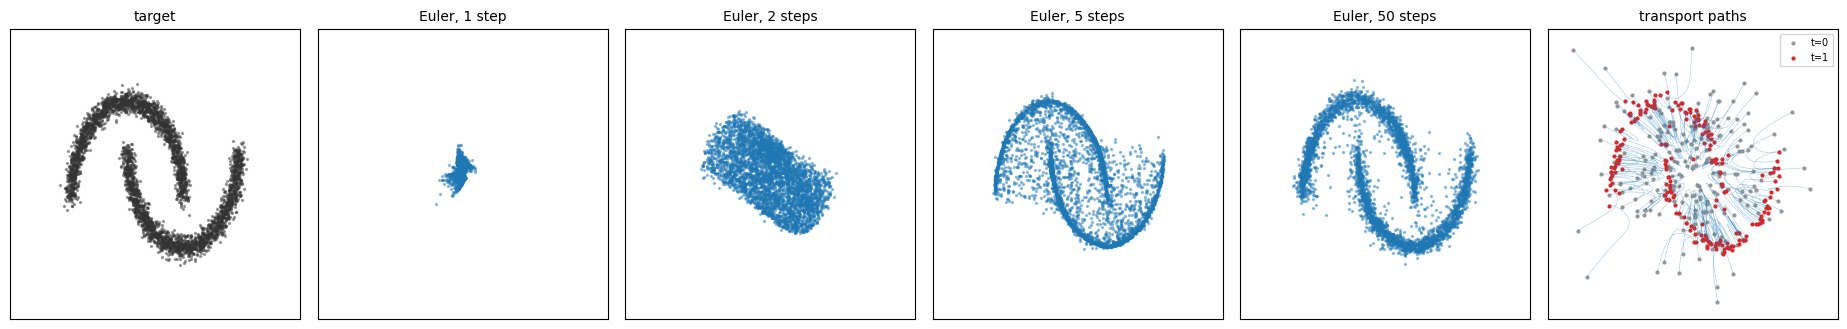

final training loss: 1.4048  (irreducible floor > 0 by construction)


In [ ]:
@torch.no_grad()
def _sample_ref(n: int, n_steps: int, method: str = "euler") -> np.ndarray:
    x0 = torch.randn(n, 2, device=DEVICE)
    return integrate(ref_model, x0, n_steps=n_steps, method=method).cpu().numpy()


ref_model.eval()
step_counts = [1, 2, 5, 50]

fig, axes = plt.subplots(1, len(step_counts) + 2, figsize=(3.1 * (len(step_counts) + 2), 3.2))

ref_pts = two_moons(4000).numpy()
axes[0].scatter(ref_pts[:, 0], ref_pts[:, 1], s=2, alpha=0.4, color="#333333")
axes[0].set_title("target", fontsize=10)

for ax, k in zip(axes[1:], step_counts):
    pts = _sample_ref(4000, k)
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.4, color="#1f77b4")
    ax.set_title(f"Euler, {k} step{'s' if k > 1 else ''}", fontsize=10)

# Transport trajectories for a handful of prior samples.
x0 = torch.randn(220, 2, device=DEVICE)
_, path = integrate(ref_model, x0, n_steps=50, return_path=True)
path = path.cpu().numpy()
axes[-1].plot(path[:, :, 0], path[:, :, 1], lw=0.35, alpha=0.45, color="#1f77b4")
axes[-1].scatter(path[0, :, 0], path[0, :, 1], s=4, color="#999999", label="t=0")
axes[-1].scatter(path[-1, :, 0], path[-1, :, 1], s=4, color="#d62728", label="t=1")
axes[-1].legend(fontsize=7, loc="upper right")
axes[-1].set_title("transport paths", fontsize=10)

for ax in axes:
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

ref_model.train()

# The objective does not drive to zero: given x_t, the conditional target x1 - x0
# stays random, and the minimiser is its conditional expectation. The residual is
# that irreducible variance, so loss value alone says nothing about sample quality.
print(f"final training loss: {np.mean(ref_hist[-500:]):.4f}  (irreducible floor > 0 by construction)")

### Findings

Both modes are recovered at 50 steps and nearly so at 5, but a single Euler step collapses to the conditional mean. Straightness holds for the conditional paths, which are lines by construction; the field the network actually learns is the marginal one, $\mathbb{E}[x_1 - x_0 \mid x_t = x]$, which near $t=0$ averages over every reachable destination and so points toward the data mean. The marginal flow is curved, and the transport-path panel shows it directly — paths leave the prior bunched and separate late.

Two consequences: step count is a quality/latency trade-off to be measured rather than assumed, and the loss has a positive floor set by the irreducible variance of $x_1 - x_0$ given $x_t$, so its value detects divergence and says nothing about sample quality.